In [3]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Literal,Annotated
from pydantic import BaseModel,Field
import operator

In [11]:
import os
import requests
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI
from langchain_core.messages import SystemMessage,HumanMessage,BaseMessage
from langgraph.checkpoint.memory import MemorySaver
from langgraph.prebuilt import ToolNode, tools_condition
from langchain_tavily import TavilySearch
from langchain_core.tools import tool
from langchain_community.tools.tavily_search import TavilySearchResults

/tmp/ipykernel_37165/144143406.py:10: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools.tavily_search import TavilySearchResults


In [9]:
import requests
import math

In [14]:
load_dotenv(override=True)

OPENAI_API_KEY = os.getenv("OPENAI_API_KEY")
ALPHA_VANTAGE_API_KEY = os.getenv("ALPHA_VANTAGE_API_KEY")
WEATHERSTACK_API_KEY = os.getenv("WEATHERSTACK_API_KEY")
TAVILY_API_KEY = os.getenv("TAVILY_API_KEY")

In [15]:
search_tool = TavilySearchResults(
    api_key=TAVILY_API_KEY,
    max_results=3,
    topic="general",
    search_depth="advanced")

@tool
def calculator(expression:str)->str:
    """
    Useful for simple match calculations.
    Input should be valid math expression.
    Example: 2+ 4, math.sqrt(16), 10 * 5
    """
    try:
        allowed = {
            "math":math,
            "abs":abs,
            "sqrt":sqrt,
            "min":min,
            "max":max,
            "sum":sum
        }
        result = eval(expression, {"__builtins__":{}}, allowed)
        return str(result)
    except Exception as e:
        return f"Calculation error: {str(e)}"

@tool
def get_stock_price(symbol: str) -> dict:
    """
    Fetch latest stock price for a given symbod (e.g. 'AAPL','TSLA')
    Using Alpha Vantage with API Key in the URL
    """
    url = f"https://www.alphavantage.co/query?function=GLOBAL_QUOTE&symbold={symbol}&apikey={ALPHA_VANTAGE_API_KEY}"
    r = requests.get(url)
    return r.json()

@tool
def get_weather_data(city: str) -> str:
    """Fetch current weather data for a city from weatherstak.com"""    
    if not WEATHERSTACK_API_KEY:
        raise ValueError("WEATHERSTACK_API_KEY is not set in the environment variables.")

    url = f"http://api.weatherstack.com/current?access_key={WEATHERSTACK_API_KEY}&query={city}"
    response = requests.get(url)
    data = response.json()

    if "error" in data:
        return f"Error fetching weather data: {data['error']['info']}"

    if "current" not in data:
        return "Error: No current weather data found."
    current_weather = data.get("current", {})
    temperature = current_weather.get("temperature")
    humidity = current_weather.get("humidity")
    weather_descriptions = current_weather.get("weather_descriptions", [])
    description = weather_descriptions[0] if weather_descriptions else "No description available"

    return {
        "city": city,
        "temperature": temperature,
        "humidity": humidity,
        "description": description
    }

/tmp/ipykernel_37165/1557004125.py:1: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  search_tool = TavilySearchResults(


In [16]:
tools = [search_tool,get_stock_price,calculator,get_weather_data]

In [17]:
bot_llm = ChatOpenAI(
    model_name="gpt-4o-mini",
    temperature=0,
    openai_api_key=OPENAI_API_KEY)


In [19]:
llm_with_tools = bot_llm.bind_tools(tools)

In [20]:
from langgraph.graph.message import add_messages

class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

In [21]:
def chat_node(state:ChatState)-> dict:
    messages = state["messages"]
    response = llm_with_tools.invoke(messages)
    return {"messages":response}


In [24]:
tool_node = ToolNode(tools)

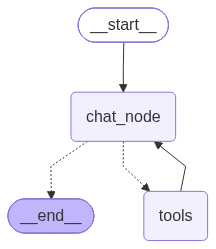

In [ ]:
checkpoint = MemorySaver()

graph = StateGraph(ChatState)

graph.add_node('chat_node',chat_node)
graph.add_node('tools',tool_node)
graph.add_node('tools',tool_node)


graph.add_edge(START,'chat_node')
graph.add_conditional_edges('chat_node',tools_condition)
graph.add_edge('tools','chat_node')
graph.add_edge('chat_node',END)

chat_bot = graph.compile(checkpointer=checkpoint)
chat_bot

In [50]:
thread_id = "1"

while True:
    user_message = input("Your Input Here: ")
    print("User Message : ",user_message)
    if user_message.strip().lower() in ["exit","quit","bye"]:
        break
    config ={"configurable": {"thread_id":thread_id}}
    message = {"messages":[HumanMessage(content=user_message)]}
    response = chat_bot.invoke(message,config=config)
    print("AI : ",response["messages"][-1].content)

User Message :  what is temprate in navi mumbai
AI :  The current temperature in Navi Mumbai is 30°C, with a humidity level of 58%. The weather is described as having a smoky haze.
User Message :  what are the movies running around Airoli
AI :  Here are some resources to find movies currently running in Airoli, Navi Mumbai:

1. **10 Theaters in Airoli, Navi Mumbai - Cinema Halls**: This link provides information about various cinema halls in Airoli that are screening Hindi, English, Tamil, Telugu, and Marathi movies. [View more here](https://www.justdial.com/Navi-Mumbai/Cinema-Halls-in-Airoli/nct-10099752).

2. **Multiplex Cinema Halls in Airoli**: This page lists multiplex cinemas in Airoli, including show timings and popular films. [Check it out here](https://www.justdial.com/Navi-Mumbai/Multiplex-Cinema-Halls-in-Airoli/nct-10332503).

3. **The top 10 theaters near Airoli**: This resource highlights the top theaters near Airoli, including their ratings and features. [Explore more her

KeyboardInterrupt: 